# Exercise 3.3: Build a Basic LangGraph Agent for Natural Language to SQL

We will now build a simple LangGraph agent that answers natural language questions
about F1 data stored in SAP HANA Cloud.

**What is LangGraph?** LangGraph is a framework for building AI agents as a graph
of steps (*nodes*). Each node performs one task — such as searching a database or
calling an LLM — and passes its results forward to the next node. This makes
complex AI workflows easy to visualise, debug, and extend.

This agent is intentionally kept simple ("naive"): it always runs all five steps in
a fixed order, with no branching, error recovery, or retries. The steps are:

1. **Retrieve** — search the vector store for database objects (tables/views) relevant to the question
2. **Get schema** — query the RDF graph for column definitions of those objects
3. **Generate SQL** — ask the LLM to write a SQL query using the question + schema
4. **Execute SQL** — run the query against SAP HANA Cloud
5. **Generate answer** — ask the LLM to turn the query result into a plain English answer

### Setup
Before building the agent, we need to connect four things:
1. SAP HANA Cloud — the database where the F1 data lives
2. An LLM via SAP AI Core — to generate SQL and natural language answers
3. The OBJECT_INDEX vector store — to search for relevant tables by meaning
4. The OBJECT_INDEX RDF graph — to look up column definitions

## Connect to SAP HANA Cloud

First, we need to connect to our SAP HANA Cloud instance (`hana-db`) running on SAP BTP. Use your database user to connect.

In [1]:
import os
from dotenv import load_dotenv
from hdbcli import dbapi

load_dotenv()

connection = dbapi.connect(
    user="DA263_000", # (replace 000 with your student number, e.g. 001)
    password=os.environ.get("HANA_DB_PASSWORD"),
    address=os.environ.get("HANA_DB_ADDRESS"),
    port=os.environ.get("HANA_DB_PORT"),
    # sslValidateCertificate = False
)

print('HANA Cloud connected:', connection.isconnected())

Error: (10, "authentication failed: Detailed info for this error can be found with correlation ID '1C233768BDC29F49842D38E1C9BC3F8A'")

## Provide an LLM

We connect to **GPT-4.1** via the **SAP Generative AI Hub**, which acts as a
managed proxy to various LLM providers (OpenAI, Anthropic, etc.) within SAP BTP.

The result is a standard LangChain `ChatOpenAI` object stored in `llm`. All agent
nodes that need language generation will call this object — they don't need to know
which underlying model is used, just that `llm` speaks the LangChain chat interface.

In [2]:
from gen_ai_hub.proxy.langchain import ChatOpenAI
from gen_ai_hub.proxy import get_proxy_client

proxy_client = get_proxy_client('gen-ai-hub')

llm = ChatOpenAI(proxy_model_name='gpt-4.1', proxy_client=proxy_client)

print("LLM model:", llm.model_name)

LLM model: gpt-4.1


## Expose the OBJECT_INDEX Table as Vector Store

In exercise 1 we created an `OBJECT_INDEX` table that stores a text description and
pre-computed **embedding** for each database object (table/view) in the ERGAST_2025
schema.

Here we wrap `OBJECT_INDEX` in a LangChain `HanaDB` vector store. When the agent
runs, it will call `similarity_search` on this object to find the tables most
relevant to the user's question. We also configure which metadata columns to return
alongside each result (schema name, object name, type) so the next node knows which
tables to look up.

In [3]:
from langchain_hana import HanaDB, HanaInternalEmbeddings

embeddings = HanaInternalEmbeddings(internal_embedding_model_id="SAP_GXY.20250407")

db = HanaDB(
    connection=connection,
    embedding=embeddings,
    table_name="OBJECT_INDEX",
    content_column="DESCRIPTION",
    metadata_column="LC_METADATA",
    vector_column="DESCRIPTION_EMBEDDING",
    specific_metadata_columns=["OBJECT_OID", "SCHEMA_NAME", "OBJECT_NAME", "OBJECT_TYPE"],
)

print("Vector store connected to OBJECT_INDEX")

NameError: name 'connection' is not defined

## Connect to the OBJECT_INDEX RDF Graph

In addition to the vector store (which finds *which* tables are relevant), we also
need structured column-level detail — the names, types, and descriptions of every
column in those tables. This is stored as an **RDF graph** in HANA Cloud.

`HanaRdfGraph` connects to the `OBJECT_INDEX_RDF_GRAPH` we built in exercise 1 and
automatically extracts its **ontology** (the set of types and relationships it
contains). The agent will use this ontology to construct valid SPARQL queries at
runtime when it needs column definitions for a specific table.

In [5]:
from langchain_hana import HanaRdfGraph

oi_graph = HanaRdfGraph(
    connection=connection,
    graph_uri="DA263_000.OBJECT_INDEX_RDF_GRAPH", # (replace 000 with your student number, e.g. 001)
    auto_extract_ontology=True,
)

### Define Agent State and Nodes

**Agent state** is a shared dictionary that flows through every node in the graph.
Think of it as a baton in a relay race — each node picks it up, does its work, adds
its result, and passes it on. At the end, the final state holds all intermediate
results alongside the final answer.

Our `AgentState` has six fields, filled in one by one as the agent runs:

| Field | Filled by | Contains |
|---|---|---|
| `user_input` | caller | the original question |
| `retrieved_objects` | `retrieve_objects` | tables found by vector search |
| `schema_context` | `get_schema` | column definitions as a text block |
| `sql_query` | `generate_sql` | the SQL written by the LLM |
| `sql_result` | `execute_sql` | raw query output |
| `final_answer` | `generate_answer` | the plain English answer |

Each of the five functions below is one **node**. A node receives the current state
and returns a *partial* update — only the fields it changed. LangGraph merges that
update back into the shared state before calling the next node.

In [6]:
import csv
import io
from typing import Optional
from typing_extensions import TypedDict
from langchain_core.messages import HumanMessage, SystemMessage


# ---------------------------------------------------------------------------
# State
# ---------------------------------------------------------------------------

class AgentState(TypedDict):
    user_input: str
    retrieved_objects: list       # objects found in the vector store
    schema_context: str           # column info retrieved from the RDF graph
    sql_query: str                # SQL generated by the LLM
    sql_result: str               # raw query output (CSV-like string)
    final_answer: str             # natural language answer
    error: Optional[str]


# ---------------------------------------------------------------------------
# Node 1 – retrieve relevant DB objects from the vector store
# ---------------------------------------------------------------------------

def retrieve_objects(state: AgentState) -> dict:
    docs = db.similarity_search_with_score(state["user_input"], k=10)
    objects = [
        {
            "schema": doc.metadata.get("SCHEMA_NAME"),
            "name":   doc.metadata.get("OBJECT_NAME"),
            "type":   doc.metadata.get("OBJECT_TYPE"),
            "description": doc.page_content,
            "score":  round(score, 3),
        }
        for doc, score in docs
    ]
    print(f"[retrieve_objects] searched: '{state["user_input"]}'")
    print(f"[retrieve_objects] found: {[o['name'] for o in objects]}")
    return {"retrieved_objects": objects}


# ---------------------------------------------------------------------------
# Node 2 – query the RDF graph for columns of each retrieved object
# ---------------------------------------------------------------------------

def get_schema(state: AgentState) -> dict:
    schema_lines = []

    for obj in state["retrieved_objects"]:
        obj_name   = obj["name"]
        schema_name = obj["schema"]
        obj_type   = obj["type"]

        sparql = f"""
PREFIX hana: <https://example.org/hana-metadata#>
PREFIX rdf:  <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
SELECT ?colName ?dataType ?comment
WHERE {{
    ?obj rdf:type  hana:DatabaseObject .
    ?obj rdfs:label "{obj_name}" .
    ?obj hana:hasColumns ?col .
    ?col rdfs:label ?colName .
    OPTIONAL {{ ?col hana:dataTypeName ?dataType }}
    OPTIONAL {{ ?col hana:comment ?comment }}
}}
ORDER BY ?colName
"""
        # print(f"SPARQL: {sparql}")
        try:
            csv_str = oi_graph.query(sparql)           # returns CSV string
            reader  = csv.DictReader(io.StringIO(csv_str))
            columns = [
                f"{row['colName']} ({row['dataType']}) {row['comment']}" if row.get("dataType") else row["colName"]
                for row in reader
            ]
        except Exception as exc:
            columns = [f"(error fetching columns: {exc})"]

        schema_lines.append(f'{obj_type} "{schema_name}"."{obj_name}"')
        schema_lines.append(f'  Description: {obj["description"][:300]}')
        schema_lines.append(f'  Columns: {", ".join(columns) if columns else "(none found)"}')
        schema_lines.append("")

    schema_context = "\n".join(schema_lines)
    print(f"[get_schema] built schema context for {len(state['retrieved_objects'])} objects")
    # print(f"[schema context]: {schema_context}")
    return {"schema_context": schema_context}


# ---------------------------------------------------------------------------
# Node 3 – generate a SQL query
# ---------------------------------------------------------------------------

def generate_sql(state: AgentState) -> dict:
    messages = [
        SystemMessage(content=(
            "You are a SQL expert for SAP HANA Cloud.\n"
            "Given the user question and the database schema below, write a single SQL SELECT query.\n"
            "Use fully qualified names in double quotes: SELECT \"columnName\" FROM \"SCHEMA\".\"OBJECT\".\n"
            "Return ONLY the SQL query — no explanation, no markdown fences."
        )),
        HumanMessage(content=(
            f"User question: {state['user_input']}\n\n"
            f"Available database objects:\n{state['schema_context']}\n\n"
            "Write a SQL query to answer the question."
        )),
    ]
    response = llm.invoke(messages)
    sql = response.content.strip()
    print(f"[generate_sql]\n{sql}")
    return {"sql_query": sql}


# ---------------------------------------------------------------------------
# Node 4 – execute the SQL against HANA Cloud
# ---------------------------------------------------------------------------

def execute_sql(state: AgentState) -> dict:
    try:
        cursor = connection.cursor()
        cursor.execute(state["sql_query"])
        col_names = [desc[0] for desc in cursor.description]
        rows = cursor.fetchmany(50)
        cursor.close()
        lines = [", ".join(col_names)] + [", ".join(str(v) for v in row) for row in rows]
        result_str = "\n".join(lines)
        print(f"[execute_sql] {len(rows)} row(s) returned")
        return {"sql_result": result_str, "error": None}
    except Exception as exc:
        print(f"[execute_sql] error: {exc}")
        return {"sql_result": "", "error": str(exc)}


# ---------------------------------------------------------------------------
# Node 5 – formulate a natural language answer
# ---------------------------------------------------------------------------

def generate_answer(state: AgentState) -> dict:
    if state.get("error") and not state.get("sql_result"):
        answer = (
            f"I could not answer your question due to an error:\n{state['error']}\n\n"
            f"SQL attempted:\n{state.get('sql_query', 'N/A')}"
        )
        return {"final_answer": answer}

    messages = [
        SystemMessage(content=(
            "You are a helpful data analyst. "
            "Answer the user's question clearly and concisely based on the SQL query results."
        )),
        HumanMessage(content=(
            f"User question: {state['user_input']}\n\n"
            f"SQL query executed:\n{state['sql_query']}\n\n"
            f"Query results:\n{state['sql_result']}\n\n"
            "Please provide a clear, concise answer."
        )),
    ]
    response = llm.invoke(messages)
    return {"final_answer": response.content}


print("Agent nodes defined")

Agent nodes defined


### Build and Compile the LangGraph Agent

Now we assemble the five nodes into a runnable graph using `StateGraph`.

- **`add_node`** registers a function under a name — the name is used to refer to it when drawing edges.
- **`add_edge`** draws a directed connection from one node to the next. `START` and `END` are special built-in markers for the entry and exit points of the graph.
- **`compile()`** validates the graph (checks for missing edges, unreachable nodes, etc.) and returns an executable `agent` object.

The result is the simple linear pipeline we described at the top of this notebook.
Run the cell and inspect the diagram — each box is a node, and the arrows show the
order of execution.

Agent compiled — graph:


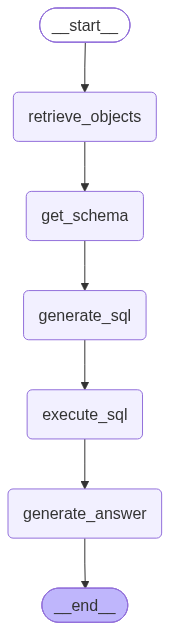

In [7]:
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

workflow = StateGraph(AgentState)

workflow.add_node("retrieve_objects", retrieve_objects)
workflow.add_node("get_schema",       get_schema)
workflow.add_node("generate_sql",     generate_sql)
workflow.add_node("execute_sql",      execute_sql)
workflow.add_node("generate_answer",  generate_answer)

workflow.add_edge(START,              "retrieve_objects")
workflow.add_edge("retrieve_objects", "get_schema")
workflow.add_edge("get_schema",       "generate_sql")
workflow.add_edge("generate_sql",     "execute_sql")
workflow.add_edge("execute_sql",      "generate_answer")
workflow.add_edge("generate_answer",  END)

agent = workflow.compile()

print("Agent compiled — graph:")
# print(agent.get_graph().draw_ascii())
display(Image(agent.get_graph().draw_mermaid_png()))

### Run the Agent

Call `agent.invoke(...)` with a dictionary containing the user's question. This
triggers the full pipeline — retrieve → schema → generate SQL → execute → answer —
and returns the final state dictionary.

The `print` statements inside each node will show you what is happening at each
step: which tables were found, what SQL was generated, and how many rows came back.
This is useful for understanding (and debugging) the agent's reasoning.

**Try it yourself:** Change `user_question` to ask anything about the F1 data.
The database contains race results, driver standings, lap times, pit stops, and
more from past Formula 1 seasons. Some example questions to get you started:

- *"Who are the top 5 drivers by total points?"*
- *"Which circuit hosted the most races?"*
- *"Which constructor had the fastest average pit stop?"*

In [8]:
user_question = "Who are the top 5 drivers by total points scored in all races?"
user_question = "Which circuit saw the most races?"
user_question = "Which driver came in second most of the times when Lewis Hamilton won?"

result = agent.invoke({"user_input": user_question})

print("\n" + "=" * 60)
print("FINAL ANSWER")
print("=" * 60)
print(result["final_answer"])

[retrieve_objects] searched: 'Which driver came in second most of the times when Lewis Hamilton won?'
[retrieve_objects] found: ['DRIVERSTANDINGS', 'PITSTOPS', 'LAPTIMES', 'RESULTS', 'DRIVERS', 'QUALIFYING', 'SPRINTRESULTS', 'CONSTRUCTORSTANDINGS', 'STATUS', 'CONSTRUCTORRESULTS']
[get_schema] built schema context for 10 objects
[generate_sql]
SELECT d2."forename", d2."surname", COUNT(*) AS "second_places"
FROM "ERGAST_2025"."RESULTS" r1
JOIN "ERGAST_2025"."DRIVERS" d1 ON r1."driverId" = d1."driverId"
JOIN "ERGAST_2025"."RESULTS" r2 ON r1."raceId" = r2."raceId" AND r2."position" = 2
JOIN "ERGAST_2025"."DRIVERS" d2 ON r2."driverId" = d2."driverId"
WHERE d1."forename" = 'Lewis' AND d1."surname" = 'Hamilton' AND r1."position" = 1
GROUP BY d2."forename", d2."surname"
ORDER BY "second_places" DESC
LIMIT 1
[execute_sql] 1 row(s) returned

FINAL ANSWER
Max Verstappen came in second most often (21 times) when Lewis Hamilton won.
